## **Load and Clean CSV Files**

### **Combine the CSV Files**

In [ ]:
import glob
from quenix_application.scopus_data import combine_csvs

csvs_paths = glob.glob("data/external/scopus/scopus_*.csv")
output_path = "data/external/scopus_2025_04_30.csv"

df = combine_csvs(csvs_paths, output_path)

### **Check duplicate DOIs**

In [ ]:
from quenix_application.scopus_data import load_csv
df = load_csv()
print(len(df))

In [ ]:
duplicate_doi_values = df["DOI"].value_counts()
duplicate_doi_values = duplicate_doi_values[duplicate_doi_values > 1]
print(f"Anzahl verschiedener mehrfacher DOIs: {len(duplicate_doi_values)}")
print(f"Anzahl an Zeilen mit mehrfacher DOI: {duplicate_doi_values.sum()}")

In [ ]:
from quenix_application.scopus_data import remove_duplicates_doi
output_path = "data/external/scopus_2025_04_30_cleaned.csv"
df_cleaned = remove_duplicates_doi(df, output_path)
print(len(df_cleaned))

## **Analyse Metadata**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("data/external/scopus_2025_04_30_cleaned.csv") 

### **Paper pro Jahr**

In [ ]:
papers_per_year = df['Year'].value_counts().sort_index()
papers_per_year = papers_per_year[papers_per_year.index >= 2000]

# Plot
plt.figure(figsize=(12, 6))
papers_per_year.plot(kind='bar')
plt.xlabel("Jahr")
plt.ylabel("Anzahl veröffentlichter Paper")
plt.title("Anzahl veröffentlichter Paper pro Jahr")
plt.tight_layout()
plt.show()

### **Zitierungen pro Jahr**

In [ ]:
# Durchschnittliche Zitierungen pro Jahr berechnen
citations_per_year = df.groupby('Year')['Cited by'].mean()
citations_per_year = citations_per_year[citations_per_year.index >= 2000]

# Plot
plt.figure(figsize=(12, 6))
citations_per_year.plot(kind='line', marker='o')
plt.xlabel("Jahr")
plt.ylabel("Durchschnittliche Zitierungen pro Paper")
plt.title("Durchschnittliche Zitierungen pro Jahr")
plt.grid(True)
plt.tight_layout()
plt.show()

### **Journal**

In [ ]:
# Häufigkeit der Journale zählen
top_journals = df['Source title'].value_counts().head(50)

# Plot
plt.figure(figsize=(12, 6))
top_journals.plot(kind='bar')
plt.xlabel("Journal")
plt.ylabel("Anzahl veröffentlichter Paper")
plt.title("Top 10 der Journale")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

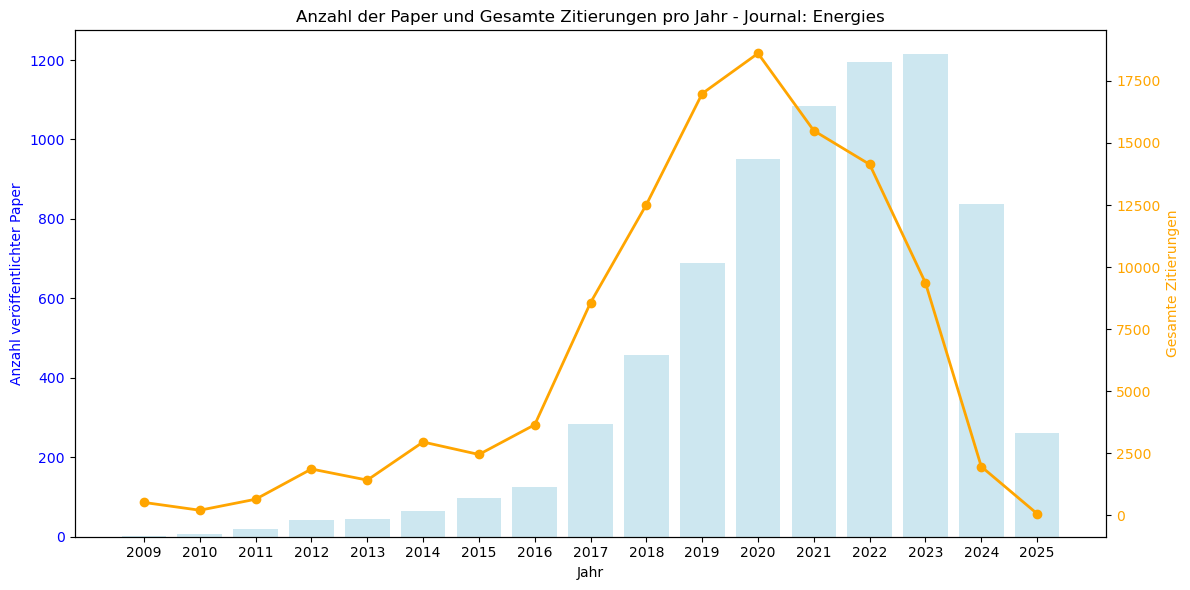

In [45]:
def plot_publications_and_citations_trend(journal_name):
    # Filter nach dem angegebenen Journal
    df_journal = df[df['Source title'] == journal_name]
    
    # Anzahl der Publikationen pro Jahr zählen
    publications_per_year = df_journal.groupby('Year').size()
    
    # Gesamte Anzahl der Zitierungen pro Jahr berechnen
    total_citations_per_year = df_journal.groupby('Year')['Cited by'].sum()
    
    # Plot erstellen
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    # Balkendiagramm für die Anzahl der Publikationen
    ax1.bar(publications_per_year.index, publications_per_year.values, color='lightblue', label='Anzahl der Paper', alpha=0.6)
    ax1.set_xlabel("Jahr")
    ax1.set_ylabel("Anzahl veröffentlichter Paper", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')
    
    # Zweite y-Achse für die gesamten Zitierungen
    ax2 = ax1.twinx()
    ax2.plot(total_citations_per_year.index, total_citations_per_year.values, color='orange', marker='o', label='Gesamte Zitierungen', linestyle='-', linewidth=2)
    ax2.set_ylabel("Gesamte Zitierungen", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')
    
    # X-Achse als Ganzzahlen formatieren
    ax1.set_xticks(publications_per_year.index)  # Setze X-Achse mit den Jahreswerten
    ax1.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x)}'))  # Ganzzahlige Darstellung ohne Komma
    
    # Titel und Layout
    plt.title(f"Anzahl der Paper und Gesamte Zitierungen pro Jahr - Journal: {journal_name}")
    fig.tight_layout()
    plt.show()

# Beispiel: Aufruf der Funktion für ein Journal
plot_publications_and_citations_trend("Energies")